# Kiểm tra dữ liệu PM2.5 Hà Nội

Chỉ chọn dòng trước 2025-11-22 00:00 UTC giả định, gồm ngày 21/11. Tài liệu nguồn ghi UTC nhưng chưa được xác minh. Số cửa sổ theo nguồn OpenAQ chỉ mang tính chẩn đoán, chưa phải dữ liệu sẵn sàng huấn luyện.

In [1]:
from pathlib import Path
import sys, platform
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_colwidth', None)
from IPython.display import display
root = Path.cwd().resolve()
if root.name == 'notebooks': root = root.parent
if not (root / 'configs/common.yaml').is_file(): raise RuntimeError('Run from project root or notebooks directory')
if str(root) not in sys.path: sys.path.insert(0, str(root))
from src.utils import load_config, sha256
from src.data_pipeline import audit_hourly, make_split_bounds, build_windows, missingness_tables, coverage_tables
from src import plots
from dataclasses import replace
def show(fig):
    display(fig)
    plt.close(fig)
config = load_config(root / 'configs/common.yaml')
data = audit_hourly(config.input_csv, config)
bounds = make_split_bounds(data.values.index, config)
display(pd.Series({'python': sys.executable, 'python_version': platform.python_version(), 'config': str(config.config_path), 'input': str(config.input_csv), 'input_sha256': sha256(config.input_csv), 'provenance': data.summary['provenance_status'], 'timezone': data.summary['timezone']}, name='value').to_frame())

,value
python,c:\Users\Lap4all\miniconda3\envs\aqi_forecast\python.exe
python_version,3.11.16
config,C:\MCU\ESP32\ESP32\ESP32_node\HN_PM25_forecasting\configs\common.yaml
input,C:\MCU\ESP32\ESP32\ESP32_node\HN_PM25_forecasting\data\Hanoi_aqi\hanoi_aqi_ml_ready_fixed.csv
input_sha256,dec855c2491a6b28bada613d4941bbde246557d2d6763a5b8ee90286b8c0da89
provenance,provenance_unverified
timezone,"UTC assumed from source dictionary, verification required"


## Phạm vi và khoảng trống

Bộ lọc áp dụng trước khi dựng lưới giờ. Bảng dưới thể hiện số dòng gốc, số dòng giữ và loại, mốc yêu cầu cùng mốc thực tế. Không thể kết luận dữ liệu liên tục chỉ vì các dòng hiện có không có ô trống.

In [2]:
display(pd.Series(data.summary).to_frame('value'))
display(data.gaps.sort_values('missing_hours', ascending=False).head(10))
display(data.source.fillna('<missing hour>').value_counts().to_frame('hours'))
display(pd.DataFrame([{'tập': name, 'bắt đầu nhãn': bound.start, 'kết thúc nhãn không gồm': bound.end_exclusive} for name,bound in bounds.items()]))

,value
input_rows,14451
selected_rows,14254
excluded_rows,197
filter,"{'start': None, 'end_exclusive': '2025-11-22T00:00:00+00:00'}"
unique_rows,14254
duplicates_removed,0
expected_hours,15509
missing_timestamps,1255
gap_count,86
observed_missing,"{'pm25': 1255, 'temperature': 1255, 'humidity': 1255}"


,start,end,missing_hours
19,2024-05-26 14:00:00+00:00,2024-06-02 02:00:00+00:00,157
10,2024-04-20 09:00:00+00:00,2024-04-26 10:00:00+00:00,146
1,2024-03-11 20:00:00+00:00,2024-03-15 10:00:00+00:00,87
46,2024-08-31 14:00:00+00:00,2024-09-03 17:00:00+00:00,76
47,2024-09-06 08:00:00+00:00,2024-09-09 03:00:00+00:00,68
79,2025-06-16 03:00:00+00:00,2025-06-18 14:00:00+00:00,60
72,2025-04-26 03:00:00+00:00,2025-04-28 12:00:00+00:00,58
32,2024-08-12 12:00:00+00:00,2024-08-14 07:00:00+00:00,44
4,2024-03-20 08:00:00+00:00,2024-03-21 15:00:00+00:00,32
73,2025-04-29 11:00:00+00:00,2025-04-30 16:00:00+00:00,30


,hours
source,
OpenAQ,12320
5-year+OpenAQ,1760
<missing hour>,1255
5-year,174


,tập,bắt đầu nhãn,kết thúc nhãn không gồm
0,train,2024-02-14 09:00:00+00:00,2025-05-11 17:00:00+00:00
1,validation,2025-05-11 17:00:00+00:00,2025-08-16 15:00:00+00:00
2,test,2025-08-16 15:00:00+00:00,2025-11-21 14:00:00+00:00


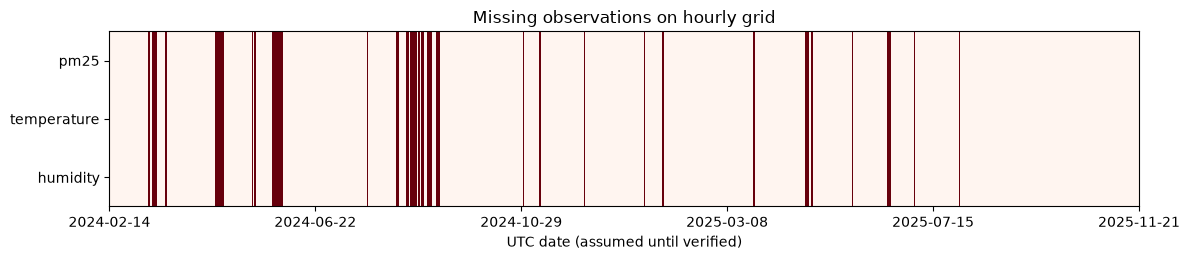

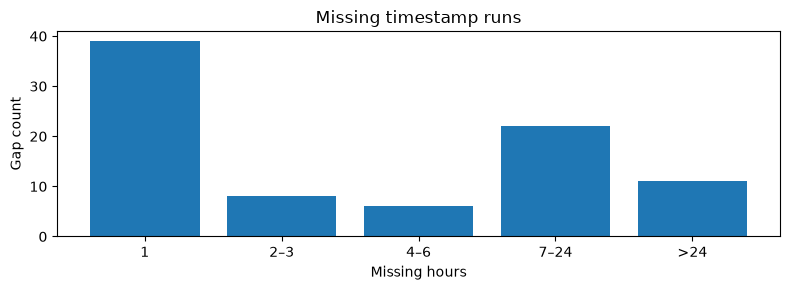

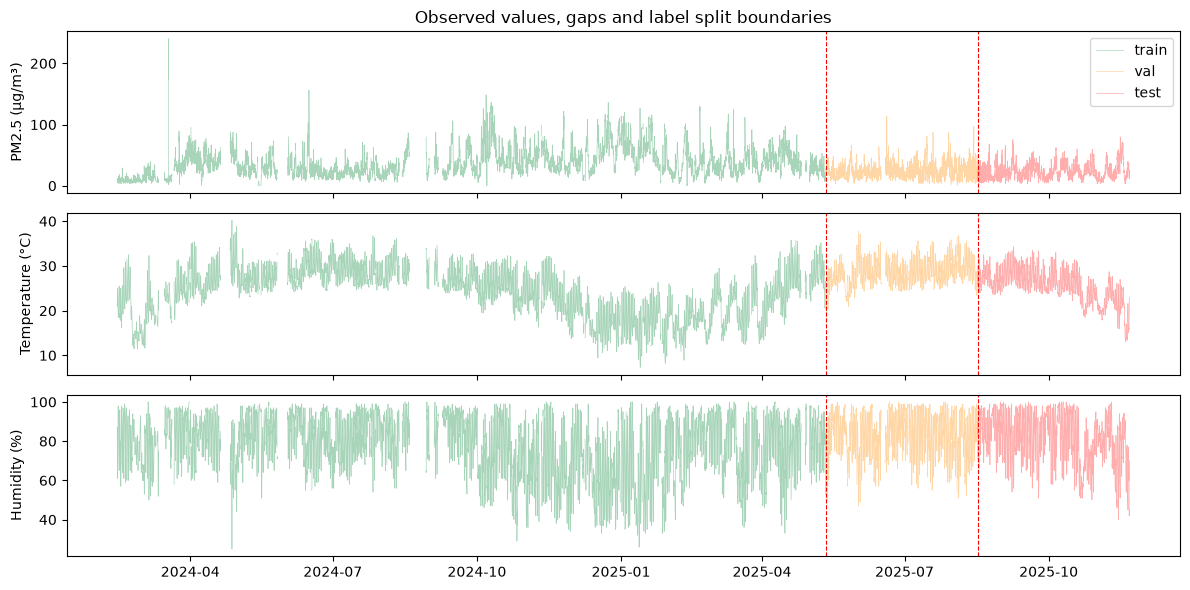

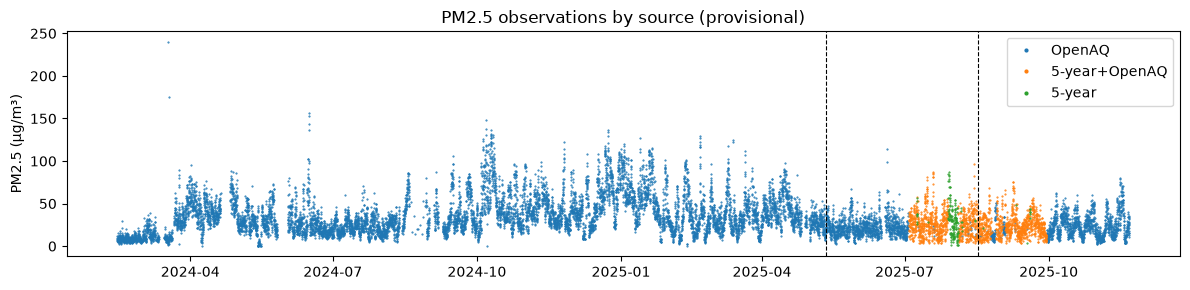

In [3]:
show(plots.plot_missingness(data.observed_mask))
show(plots.plot_gap_histogram(data.gaps))
show(plots.plot_series(data, bounds))
show(plots.plot_source_series(data, bounds))

## Ô thiếu và chuỗi thiếu

Mẫu số là số mốc giờ trên lưới, bao gồm cả mốc không có dòng và ô thiếu trong dòng có sẵn. Giờ địa phương chỉ đúng khi giả định UTC của nguồn được xác minh.

,feature,bucket_hours,runs
0,pm25,1,39
1,pm25,2-3,8
2,pm25,4-6,6
3,pm25,7-24,22
4,pm25,>24,11
5,temperature,1,39
6,temperature,2-3,8
7,temperature,4-6,6
8,temperature,7-24,22
9,temperature,>24,11


,feature,month_utc,hour_positions,missing_cells,absent_timestamp_cells,present_row_missing_cells,missing_ratio
0,humidity,2024-02,375,0,0,0,0.000000
1,humidity,2024-03,744,151,151,0,0.202957
2,humidity,2024-04,720,148,148,0,0.205556
3,humidity,2024-05,744,158,158,0,0.212366
4,humidity,2024-06,720,34,34,0,0.047222
...,...,...,...,...,...,...,...
61,temperature,2025-07,744,14,14,0,0.018817
62,temperature,2025-08,744,2,2,0,0.002688
63,temperature,2025-09,720,0,0,0,0.000000
64,temperature,2025-10,744,0,0,0,0.000000


,feature,local_hour_assumed_utc,hour_positions,missing_cells,absent_timestamp_cells,present_row_missing_cells,missing_ratio
0,humidity,0,646,39,39,0,0.060372
1,humidity,1,646,50,50,0,0.077399
2,humidity,2,646,49,49,0,0.075851
3,humidity,3,646,51,51,0,0.078947
4,humidity,4,646,56,56,0,0.086687
...,...,...,...,...,...,...,...
67,temperature,19,647,54,54,0,0.083462
68,temperature,20,647,53,53,0,0.081917
69,temperature,21,646,54,54,0,0.083591
70,temperature,22,646,55,55,0,0.085139


,feature,source,hour_positions,missing_cells,absent_timestamp_cells,present_row_missing_cells,missing_ratio
0,humidity,5-year,174,0,0,0,0.0
1,humidity,5-year+OpenAQ,1760,0,0,0,0.0
2,humidity,<timestamp absent>,1255,1255,1255,0,1.0
3,humidity,OpenAQ,12320,0,0,0,0.0
4,pm25,5-year,174,0,0,0,0.0
5,pm25,5-year+OpenAQ,1760,0,0,0,0.0
6,pm25,<timestamp absent>,1255,1255,1255,0,1.0
7,pm25,OpenAQ,12320,0,0,0,0.0
8,temperature,5-year,174,0,0,0,0.0
9,temperature,5-year+OpenAQ,1760,0,0,0,0.0


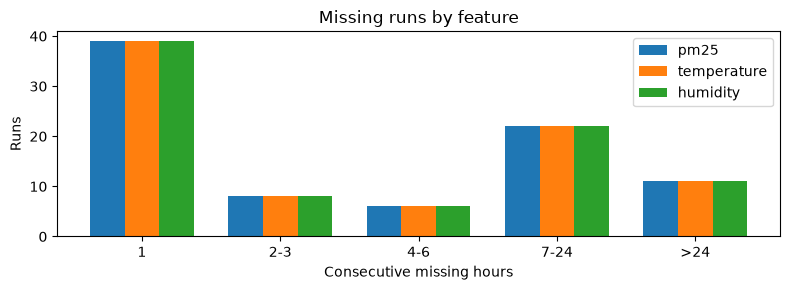

In [4]:
missing = missingness_tables(data)
display(missing['data_feature_missing_histogram'])
display(missing['data_missing_by_month'])
display(missing['data_missing_by_local_hour'])
display(missing['data_missing_by_source'])
show(plots.plot_feature_missing_histogram(missing['data_feature_missing_histogram']))

## Cửa sổ tạm tính và điền thiếu

Chỉ các dòng ứng viên OpenAQ được xét cho cả ba biến. Lịch sử đầu vào được nội suy tuyến tính giữa hai quan sát gốc trong chính 24 giờ, tối đa ba giờ thiếu liên tiếp, không ngoại suy. Tại origin phải đủ ba giá trị quan sát, nhãn tương lai không được điền. Không có dữ liệu nguồn nào được sửa.

,provisional_windows,without_fill,imputed_cells
split,,,
train,7967,7434,1977
validation,1062,1042,180
test,1255,1241,42


,rejected origins
reason,
origin_unobserved,3189
label_missing,1246
history_missing,744
insufficient_history,23
split_boundary,23


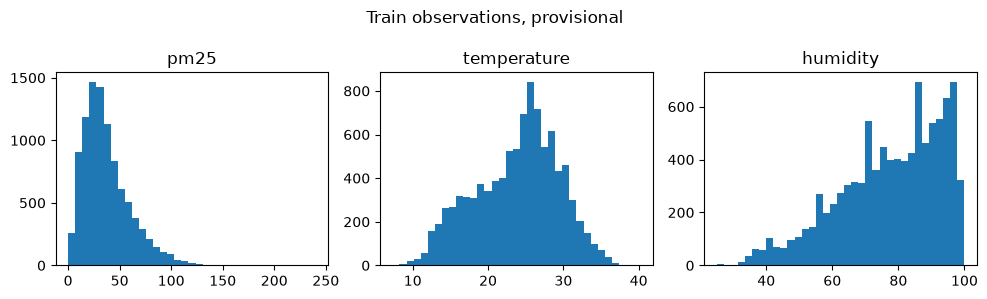

In [5]:
candidate = data.observed_mask & pd.DataFrame({feature: data.source.isin(config.allowed_sources) for feature in data.values.columns})
diagnostic = replace(data, trusted_mask=candidate)
windows = build_windows(diagnostic, bounds, config)
baseline = build_windows(diagnostic, bounds, replace(config, max_gap_hours=0))
display(pd.DataFrame([{'split': k, 'provisional_windows': len(w.origins), 'without_fill': len(baseline[k].origins), 'imputed_cells': int(w.imputed_mask.sum())} for k,w in windows.items()]).set_index('split'))
display(next(iter(windows.values())).rejections.reason.value_counts().to_frame('rejected origins'))
show(plots.plot_train_distribution(data, bounds))

In [6]:
metadata = pd.concat([w.metadata for w in windows.values()], ignore_index=True)
metadata['month'] = pd.to_datetime(metadata.origin, utc=True).dt.strftime('%Y-%m')
coverage = metadata.groupby(['split','month','source'], dropna=False).agg(windows=('origin','size'), imputed_cells=('imputed_count','sum'))
display(coverage)

windows  imputed_cells
split      month   source                        
test       2025-08 OpenAQ       31             42
           2025-09 OpenAQ       10              0
           2025-10 OpenAQ      744              0
           2025-11 OpenAQ      470              0
train      2024-02 OpenAQ      352              0
           2024-03 OpenAQ      362            189
           2024-04 OpenAQ      490            132
           2024-05 OpenAQ      368            276
           2024-06 OpenAQ      536            387
           2024-07 OpenAQ      662            243
           2024-08 OpenAQ      286            126
           2024-09 OpenAQ      490             66
           2024-10 OpenAQ      646              3
           2024-11 OpenAQ      611             66
           2024-12 OpenAQ      623             66
           2025-01 OpenAQ      547             33
           2025-02 OpenAQ      620            132
           2025-03 OpenAQ      617            192
           2025-04 OpenAQ      579              0
           2025-05 OpenAQ      178             66
validation 2025-05 OpenAQ      420            180
           2025-06 OpenAQ      613              0
           2025-07 OpenAQ       29              0

## Ranh giới nhãn và độ bao phủ

Mỗi tập được chia theo toàn bộ giờ trong khoảng đã lọc. Số giờ thuộc miền nhãn khác số origin được giữ. Các bảng cho thấy cả tháng không có mẫu, tỷ lệ cửa sổ và ô được điền cùng kết quả không điền.

,split,label_domain_hours,retained_origins,no_fill_origins,imputed_windows,imputed_window_ratio,imputed_cells,imputed_cell_ratio
0,train,10856,7967,7434,533,0.066901,1977,0.003447
1,validation,2326,1062,1042,20,0.018832,180,0.002354
2,test,2327,1255,1241,14,0.011155,42,0.000465


,split,month,season,label_domain_hours,retained_origins,no_fill_origins,imputed_windows,imputed_cells
0,train,2024-02,DJF,375,351,351,0,0
1,train,2024-03,MAM,744,363,336,27,189
2,train,2024-04,MAM,720,489,445,44,132
3,train,2024-05,MAM,744,369,281,88,276
4,train,2024-06,JJA,720,535,426,109,387
5,train,2024-07,JJA,744,662,620,42,243
6,train,2024-08,JJA,744,287,266,21,126
7,train,2024-09,SON,720,489,467,22,66
8,train,2024-10,SON,744,647,646,1,3
9,train,2024-11,SON,720,610,588,22,66


,split,season,label_domain_hours,retained_origins,no_fill_origins,imputed_windows,imputed_cells
0,test,JJA,369,31,17,14,42
1,test,SON,1958,1224,1224,0,0
2,train,DJF,2535,2141,2070,71,231
3,train,JJA,2208,1484,1312,172,756
4,train,MAM,3929,2596,2351,245,855
5,train,SON,2184,1746,1701,45,135
6,validation,JJA,1839,643,643,0,0
7,validation,MAM,487,419,399,20,180


,split,month,source,label_domain_source_hours,retained_origins,no_fill_origins
0,train,2024-02,OpenAQ,375,351,351
1,train,2024-03,<missing>,151,0,0
2,train,2024-03,OpenAQ,593,363,336
3,train,2024-04,<missing>,148,0,0
4,train,2024-04,OpenAQ,572,489,445
5,train,2024-05,<missing>,158,0,0
6,train,2024-05,OpenAQ,586,369,281
7,train,2024-06,<missing>,34,0,0
8,train,2024-06,OpenAQ,686,535,426
9,train,2024-07,<missing>,5,0,0


,count,min,max,mean
split,,,,
test,3,14,1224,418.333333
train,73,1,697,109.136986
validation,4,20,464,265.500000


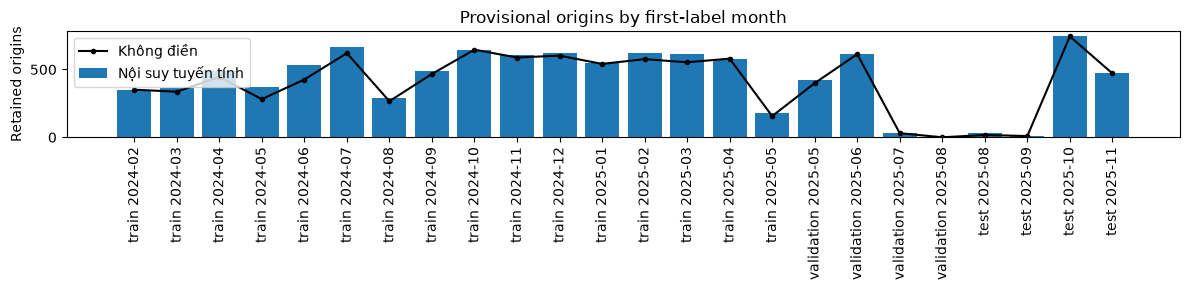

In [7]:
coverage_reports = coverage_tables(data, bounds, windows, baseline)
display(coverage_reports['data_coverage_split'])
display(coverage_reports['data_coverage_month'])
display(coverage_reports['data_coverage_season'])
display(coverage_reports['data_coverage_source'])
display(coverage_reports['data_coverage_blocks'].groupby('split').length_hours.agg(['count','min','max','mean']))
show(plots.plot_coverage(coverage_reports['data_coverage_month']))

## Ví dụ nội suy trong cửa sổ thực tế

Hai điểm neo và các giá trị nội suy đều thuộc lịch sử kết thúc tại origin. Dữ liệu OpenAQ dưới đây chỉ là ứng viên, nguồn gốc chưa được xác minh.

Tập: train , origin: 2024-03-18 18:00:00+00:00 , neo trái: 2024-03-18 03:00:00+00:00 , neo phải: 2024-03-18 05:00:00+00:00


,thời điểm,PM2.5,nội suy
8,2024-03-18 03:00:00+00:00,174.74,False
9,2024-03-18 04:00:00+00:00,88.68,True
10,2024-03-18 05:00:00+00:00,2.62,False


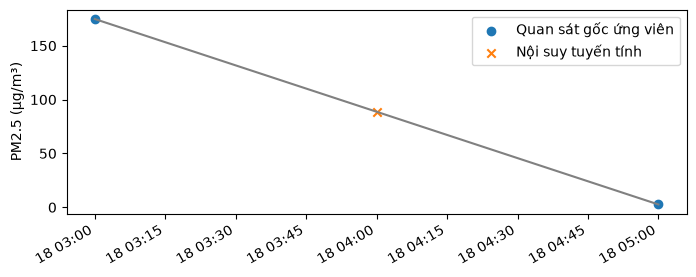

In [8]:
import numpy as np
selected_split, selected_window, selected_row = next(
    (name, window, int(np.flatnonzero(window.imputed_mask[:, :, 0].any(axis=1))[0]))
    for name, window in windows.items() if window.imputed_mask[:, :, 0].any()
)
origin = selected_window.origins[selected_row]
mask = selected_window.imputed_mask[selected_row, :, 0]
first = int(np.flatnonzero(mask)[0])
left = pd.Timestamp(int(selected_window.left_donor_times[selected_row, first, 0]), unit='ns', tz='UTC')
right = pd.Timestamp(int(selected_window.right_donor_times[selected_row, first, 0]), unit='ns', tz='UTC')
index = pd.date_range(origin - pd.Timedelta(hours=23), origin, freq='h')
example = pd.DataFrame({'thời điểm': index, 'PM2.5': selected_window.X_raw[selected_row, :, 0], 'nội suy': mask})
example = example[(example['thời điểm'] >= left) & (example['thời điểm'] <= right)]
print('Tập:', selected_split, ', origin:', origin, ', neo trái:', left, ', neo phải:', right)
display(example)
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(example['thời điểm'], example['PM2.5'], '-', color='gray')
ax.scatter(example.loc[~example['nội suy'], 'thời điểm'], example.loc[~example['nội suy'], 'PM2.5'], label='Quan sát gốc ứng viên')
ax.scatter(example.loc[example['nội suy'], 'thời điểm'], example.loc[example['nội suy'], 'PM2.5'], marker='x', label='Nội suy tuyến tính')
ax.set_ylabel('PM2.5 (µg/m³)')
ax.legend()
fig.autofmt_xdate()
show(fig)

Cần xác minh nguồn, trạm, đơn vị PM2.5, múi giờ, tiền xử lý và thời điểm công bố trước khi tạo dataset ready. Chưa huấn luyện mô hình.